# Task 3

## Setup: Imports, Dependencies and Paths

In [1]:
!pip install ultralytics

# TODO: Add all dependencies

In [2]:
from __future__ import annotations # TODO: Is this needed?
import json
import os
import random
import shutil
from pathlib import Path
from typing import Dict, List
import numpy as np
import yaml
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

%matplotlib inline

# TODO: Put all imports here

In [3]:
# Directory from where the notebook is being executed
HERE = Path.cwd()
REPO = HERE.parent # Parent of current directory

# Dataset directory
DATASET_DIR = (HERE / "../8-BallPool.v2i.yolov8").resolve() # TODO: Change this to the actual dataset directory
DATA_YAML = DATASET_DIR / "data.yaml"

# Model and runs directories
MODEL_PT = HERE / "model.pt"
RUNS_DIR = HERE / "runs"

# Check directories
print("Working directory:", HERE)
print("Dataset directory:", DATASET_DIR)

Working directory: /home/vanessa/Dados/Uni/4ano/2semestre/VC/ComputerVision/task3
Dataset directory: /home/vanessa/Dados/Uni/4ano/2semestre/VC/ComputerVision/8-BallPool.v2i.yolov8


## Part 1 - Ball Detection on 8-Ball Pool Table Images

### 1.1 Data Preparation

The dataset is already in YOLOv8 format, with `images/` and `labels/` folders and a train/valid/test split. The only adaptation needed is on the labels: the export ships five classes alphabetically (`Black`, `Cue`, `Dot`, `Solid`, `Striped`), so we drop the `Dot` annotations and remap the remaining class ids into the fixed `CLASS_NAMES` order, then write a four-class `data.yaml`.

In [4]:
# Mapping from (lower-cased) source class names to the YOLO class ids used for ball detection
NAME_TO_CLASS: Dict[str, int] = { # TODO: Is this needed?
    "cue": 0,
    "solid": 1,
    "striped": 2,
    "black": 3,
}

# Classes to be used in the dataset
CLASS_NAMES: List[str] = ["cue", "solid", "striped", "black"]

# Random seed for reproducibility
SEED = 42

In [5]:
def prepare_dataset(dataset_dir: Path) -> Path:
    """Adapt a locally downloaded YOLOv8 dataset for four-class ball detection"""
    #set_seeds() # TODO: Remove? (This is used to ensure reproducibility)

    # Load the dataset config
    data_yaml = dataset_dir / "data.yaml"
    if not data_yaml.exists():
        raise FileNotFoundError(
            f"No data.yaml found in {dataset_dir}. Download the dataset from "
            "Roboflow Universe in YOLOv8 format and extract it there."
        )
    with data_yaml.open("r", encoding="utf-8") as handle:
        cfg = yaml.safe_load(handle)
    names = [str(n) for n in cfg.get("names", [])]

    # Already adapted (names match our four classes): nothing to do.
    if names == CLASS_NAMES:
        print(f"[prepare] {data_yaml} already has the four ball classes; skipping")
        return data_yaml

    # Map each source class id to our class id. Ids whose name is missing from
    # NAME_TO_CLASS (i.e. "Dot") are dropped from the labels below.
    remap: Dict[int, int] = {}
    for src_idx, name in enumerate(names):
        our_id = NAME_TO_CLASS.get(name.strip().lower())
        if our_id is not None:
            remap[src_idx] = our_id
    print(f"[prepare] source classes {names} -> remap {remap}")

    # Rewrite every label file in place: drop dropped-class lines and remap ids.
    # Roboflow names the validation split 'valid'; our data.yaml maps it to 'val'.
    split_counts: Dict[str, int] = {}
    dropped = 0
    for split in ("train", "valid", "test"):
        label_dir = dataset_dir / split / "labels"
        if not label_dir.is_dir():
            continue
        n_images = 0
        for label_file in label_dir.glob("*.txt"):
            kept_lines: List[str] = []
            for line in label_file.read_text(encoding="utf-8").splitlines():
                parts = line.split()
                if not parts:
                    continue
                src_cls = int(parts[0])
                if src_cls not in remap:
                    dropped += 1
                    continue
                kept_lines.append(" ".join([str(remap[src_cls]), *parts[1:]]))
            label_file.write_text("\n".join(kept_lines), encoding="utf-8")
            n_images += 1
        split_counts[split] = n_images

    print(
        "[prepare] split sizes -> "
        + ", ".join(f"{k}: {v}" for k, v in split_counts.items())
        + f"; dropped {dropped} non-ball (Dot) annotations"
    )

    # Write a data.yaml describing the four-class dataset. An absolute 'path'
    # avoids the relative '../' quirk in Roboflow's own data.yaml, and pointing
    # 'val' at the 'valid' folder matches Roboflow's directory naming.
    yaml_text = (
        f"path: {dataset_dir.resolve()}\n"
        f"train: train/images\n"
        f"val: valid/images\n"
        f"test: test/images\n"
        f"nc: {len(CLASS_NAMES)}\n"
        f"names: {CLASS_NAMES}\n"
    )
    data_yaml.write_text(yaml_text, encoding="utf-8")
    print(f"[prepare] wrote dataset config to {data_yaml}")
    return data_yaml

In [6]:
DATA_YAML = prepare_dataset(DATASET_DIR)
DATA_YAML

[prepare] /home/vanessa/Dados/Uni/4ano/2semestre/VC/ComputerVision/8-BallPool.v2i.yolov8/data.yaml already has the four ball classes; skipping


PosixPath('/home/vanessa/Dados/Uni/4ano/2semestre/VC/ComputerVision/8-BallPool.v2i.yolov8/data.yaml')

### 1.2 Fine-Tune YOLOv8

We start from a pretrained YOLOv8 checkpoint and fine-tune on the prepared dataset.

In [7]:
def train_model(data_yaml: Path, model_name: str, epochs: int, imgsz: int, batch: int, device: str, project: Path, run_name: str) -> Path:
    """Fine-tune a pretrained YOLOv8 detector and return the best weights path."""
    #set_seeds() # TODO: Remove? (This is used to ensure reproducibility)

    print(f"[train] Loading pretrained model: {model_name}")
    model = YOLO(model_name)

    print(
        f"[train] Training for {epochs} epochs (imgsz={imgsz}, batch={batch}, "
        f"device={device})"
    )
    model.train(
        data=str(data_yaml),
        epochs=epochs,
        imgsz=imgsz,
        batch=batch,
        device=device,
        seed=SEED,
        project=str(project),
        name=run_name,
        exist_ok=True,
        # Data augmentation suited to a fixed top-ish table view: flips and mild
        # colour jitter help, but we keep large rotations off since balls and the
        # table framing are fairly canonical.
        fliplr=0.5,
        flipud=0.5,
        hsv_h=0.015,
        hsv_s=0.4,
        hsv_v=0.4,
        degrees=0.0,
        translate=0.05,
        scale=0.3,
        mosaic=1.0,
        patience=max(10, epochs // 5),
        verbose=True,
    )

    best = project / run_name / "weights" / "best.pt"
    print(f"[train] Best checkpoint: {best}")

    # Also drop a copy at the conventional task3/model.pt location.
    if best.exists():
        shutil.copy2(best, MODEL_PT)
        print(f"[train] Copied best weights to {MODEL_PT}")
    return best

In [8]:
MODEL_NAME = "yolov8n.pt"
EPOCHS = 1 # TODO: Change back to 100
IMGSZ = 832
BATCH = 4
DEVICE = "0"  # "0" for first GPU, or "cpu"
RUN_NAME = "ball_detection"

best_weights = train_model(DATA_YAML, MODEL_NAME, EPOCHS, IMGSZ, BATCH, DEVICE, RUNS_DIR, RUN_NAME)
best_weights

[train] Loading pretrained model: yolov8n.pt
[train] Training for 1 epochs (imgsz=832, batch=4, device=0)
Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.12.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 3770MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/vanessa/Dados/Uni/4ano/2semestre/VC/ComputerVision/8-BallPool.v2i.yolov8/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.4, hsv_v=0.4, imgsz=832, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0

PosixPath('/home/vanessa/Dados/Uni/4ano/2semestre/VC/ComputerVision/task3/runs/ball_detection/weights/best.pt')

### 1.3 Evaluate

In [9]:
def evaluate_model(weights: Path, data_yaml: Path, imgsz: int, device: str, split: str) -> Dict[str, float]:
    """Evaluate a checkpoint on a split and print mAP@0.5 plus related metrics."""
    #set_seeds() # TODO: Remove? (This is used to ensure reproducibility)

    print(f"[eval] Loading weights: {weights}")
    model = YOLO(str(weights))
    metrics = model.val(data=str(data_yaml), imgsz=imgsz, device=device, split=split, verbose=True)

    box = metrics.box
    summary = {
        "mAP@0.5": float(box.map50),
        "mAP@0.5:0.95": float(box.map),
        "precision": float(box.mp),
        "recall": float(box.mr),
    }
    print(f"[eval] split={split} results:")
    for key, value in summary.items():
        print(f"[eval]   {key}: {value:.4f}")

    # Per-class mAP@0.5 for the report.
    try:
        for idx, name in enumerate(CLASS_NAMES):
            print(f"[eval]   AP@0.5[{name}]: {float(box.ap50[idx]):.4f}")
    except (IndexError, TypeError):
        pass
    return summary

In [10]:
EVAL_SPLIT = "test"  # one of "train", "val", "test"

metrics_summary = evaluate_model(MODEL_PT, DATA_YAML, IMGSZ, DEVICE, EVAL_SPLIT)
metrics_summary

[eval] Loading weights: /home/vanessa/Dados/Uni/4ano/2semestre/VC/ComputerVision/task3/model.pt
Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.12.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 3770MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 376.0±64.8 MB/s, size: 157.7 KB)
val: Scanning /home/vanessa/Dados/Uni/4ano/2semestre/VC/ComputerVision/8-BallPool.v2i.yolov8/test/labels.cache... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 4.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3it/s 1.5s3.3s
                   all         20        226     0.0328      0.078     0.0287     0.0115
                   cue         20         20          0          0          0          0
                 solid         18         92       0.12      0.217     0.0828     0.0315
               striped         18         95    

{'mAP@0.5': 0.028654548879423654,
 'mAP@0.5:0.95': 0.011470539923014117,
 'precision': 0.03282806315514766,
 'recall': 0.07803203661327231}

### 1.4 Predict

Run detection over the images listed in an input JSON and write detections. Output format (one entry per input image):

```json
{
  "results": [
    {
      "image": "image1.jpg",
      "num_balls": 12,
      "balls": [
        {"class": "solid", "confidence": 0.91,
         "xmin": 0.31, "ymin": 0.25, "xmax": 0.35, "ymax": 0.29}
      ]
    }
  ]
}
```

Box coordinates are normalised to the `[0, 1]` range.

In [11]:
def resolve_image_path(entry: str, base_dir: Path) -> Path:
    """Resolve an image path from the input JSON.

    Tries the path as given, then relative to the input JSON's directory, its
    parent, and the current working directory. This tolerates input files whose
    paths are written relative to a different root (e.g. the Task 1 layout).
    """
    path = Path(entry)
    if path.is_absolute():
        return path
    for base in (Path.cwd(), base_dir, base_dir.parent, base_dir.parent.parent):
        candidate = base / entry
        if candidate.exists():
            return candidate
    return path


def predict(
    weights: Path,
    input_json: Path,
    output_json: Path,
    imgsz: int,
    device: str,
    conf: float,
) -> None:
    """Run detection over the images in ``input_json`` and write detections."""
    #set_seeds() # TODO: Remove? (This is used to ensure reproducibility)
    from ultralytics import YOLO

    with input_json.open("r", encoding="utf-8") as handle:
        spec = json.load(handle)
    # Accept both the documented "images" key and Task 1's "image_path" key.
    image_entries = spec.get("images") or spec.get("image_path") or []
    base_dir = input_json.parent
    print(f"[predict] {len(image_entries)} images to process")

    model = YOLO(str(weights))
    results = []
    for entry in image_entries:
        image_path = resolve_image_path(entry, base_dir)
        record = {"image": os.path.basename(entry), "num_balls": 0, "balls": []}
        if not image_path.exists():
            print(f"[predict] WARNING missing image, skipping: {image_path}")
            results.append(record)
            continue
        try:
            prediction = model.predict(
                source=str(image_path),
                imgsz=imgsz,
                device=device,
                conf=conf,
                verbose=False,
            )[0]
            h, w = prediction.orig_shape
            for box in prediction.boxes:
                cls_id = int(box.cls.item())
                x1, y1, x2, y2 = box.xyxy[0].tolist()
                record["balls"].append(
                    {
                        "class": CLASS_NAMES[cls_id]
                        if 0 <= cls_id < len(CLASS_NAMES)
                        else str(cls_id),
                        "confidence": round(float(box.conf.item()), 4),
                        "xmin": round(x1 / w, 6),
                        "ymin": round(y1 / h, 6),
                        "xmax": round(x2 / w, 6),
                        "ymax": round(y2 / h, 6),
                    }
                )
            record["num_balls"] = len(record["balls"])
            print(f"[predict] {record['image']}: {record['num_balls']} balls")
        except Exception as exc:  # noqa: BLE001 - log and continue per quality rules
            print(f"[predict] ERROR processing {image_path}: {exc}")
        results.append(record)

    # Sanity check mandated by the project quality rules.
    assert len(results) == len(image_entries), "output entries must match input"

    output_json.parent.mkdir(parents=True, exist_ok=True)
    with output_json.open("w", encoding="utf-8") as handle:
        json.dump({"results": results}, handle, indent=2)
    print(f"[predict] wrote {len(results)} results to {output_json}")

In [12]:
INPUT_JSON = HERE / "../example_json/input.json"
OUTPUT_JSON = HERE / "detection_results.json"
CONF = 0.25

predict(MODEL_PT, INPUT_JSON, OUTPUT_JSON, IMGSZ, DEVICE, CONF)

[predict] 50 images to process
[predict] 106_png.rf.28ee53acf89d9e7f17b2fb26185597a0.jpg: 0 balls
[predict] 10a_png.rf.bdc9984ba169594ea32b012098ad10dd.jpg: 0 balls
[predict] 110_png.rf.9a38b6057e543f83b58aa59b9748688b.jpg: 0 balls
[predict] 114_png.rf.98b2144c25b9f48816abd7edb00f365c.jpg: 0 balls
[predict] 115_png.rf.ed51d53dd5c384b1f26a2b6ece52ad69.jpg: 0 balls
[predict] 117_png.rf.8cc2251ee5c44b6bd3734b39795c7cc9.jpg: 0 balls
[predict] 119_png.rf.eff91a09289a82f634d7b231b06dbbdd.jpg: 0 balls
[predict] 11f_png.rf.eb0169eccfb6b264a582491457ff37b6.jpg: 0 balls
[predict] 121_png.rf.782a44b8496f239b5f996a6ed498e63a.jpg: 0 balls
[predict] 122_png.rf.7df85841dad9a1f2d79c7f510f562052.jpg: 0 balls
[predict] 123_png.rf.c77820fd3abbca5d6265af63564f9564.jpg: 0 balls
[predict] 127_png.rf.9f6501b0ba0e856cf6dd9e59f65ce574.jpg: 0 balls
[predict] 128_png.rf.536c0efc16ea6cf15f4f2a6f280450cf.jpg: 0 balls
[predict] 129_png.rf.eb2bbec526ed5285770c494673de2c04.jpg: 0 balls
[predict] 12t_png.rf.80855510c9

Show some predictions:

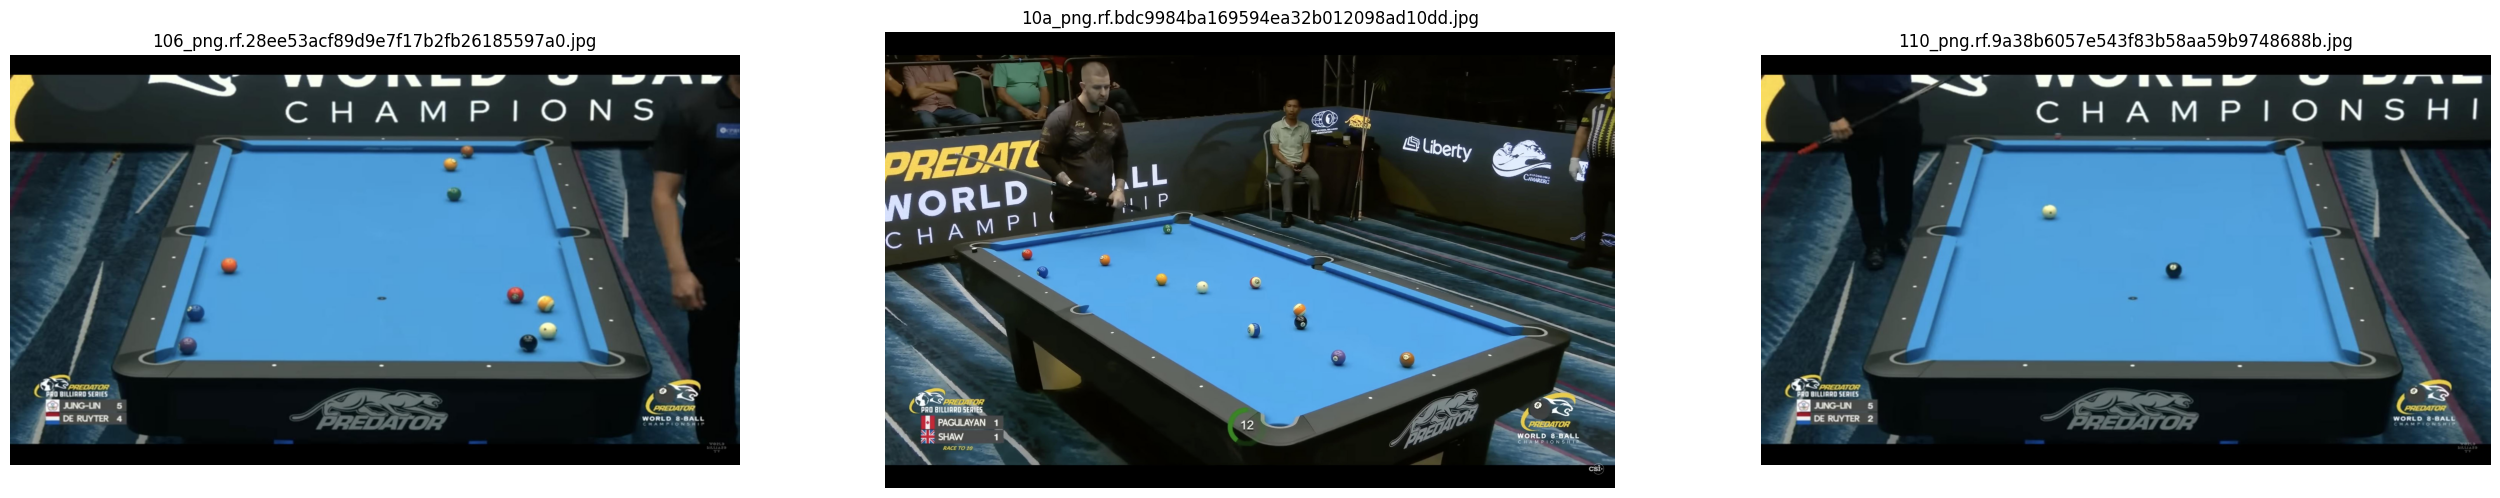

In [ ]:
# Load input and output JSONs
with OUTPUT_JSON.open("r", encoding="utf-8") as handle:
    out = json.load(handle)
with INPUT_JSON.open("r", encoding="utf-8") as handle:
    spec = json.load(handle)
entries = spec.get("images") or spec.get("image_path") or []

NUM_IMAGES = 3

# Show the first few detections with bounding boxes drawn on the images.
n_show = min(NUM_IMAGES, len(out["results"]))

f, axarr = plt.subplots(1, NUM_IMAGES, figsize=(32, 10)) 
for i in range(n_show):
    # Retrieve the detection result and corresponding image path.
    result = out["results"][i]
    img_path = resolve_image_path(entries[i], INPUT_JSON.parent)
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    # Draw bounding boxes and class labels on the image.
    for ball in result["balls"]:
        p1 = (int(ball["xmin"] * w), int(ball["ymin"] * h))
        p2 = (int(ball["xmax"] * w), int(ball["ymax"] * h))
        cv2.rectangle(img, p1, p2, (255, 0, 0), 2)
        cv2.putText(img, ball["class"], (p1[0], max(0, p1[1] - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)

    # Display the image with detections
    axarr[i].imshow(img, cmap="gray", vmin=0, vmax=255)
    axarr[i].set_title(result["image"])
    axarr[i].axis("off")

## Part 2 - Table Retrieval

In [14]:
#TODO